# Filtros lineares e não lineares
Implementação manual dos filtros de **média, mediana, moda e máxima**, utilizando a imagem `camera` do `skimage`, originalmente em escala de cinza.

O filtro de média usa convolução manual. Mediana, moda e máxima são operações **não lineares** sobre uma vizinhança: não são convoluções.

Nenhuma função do OpenCV ou filtro pronto é utilizado. NumPy é usado para armazenar matrizes; skimage, para carregar a imagem; Matplotlib, para exibir os resultados.

**Execução:** execute as células na ordem. Se necessário, descomente a instalação abaixo.

In [1]:
# %pip install numpy matplotlib scikit-image

import numpy as np
import matplotlib.pyplot as plt
from skimage import data

## 1. Funções auxiliares
As janelas devem ter tamanho ímpar e positivo. Nas bordas, replicamos o pixel mais próximo por controle manual dos índices. Assim, o resultado mantém as dimensões da imagem original.

In [2]:
def validar_entrada(imagem, tamanho):
    if imagem.ndim != 2 or imagem.size == 0:
        raise ValueError("A imagem deve ser uma matriz 2D não vazia.")
    if not isinstance(tamanho, (int, np.integer)) or tamanho < 1 or tamanho % 2 == 0:
        raise ValueError("O tamanho deve ser um inteiro ímpar e positivo.")


def pixel_com_borda(imagem, linha, coluna):
    altura, largura = imagem.shape
    linha = min(max(linha, 0), altura - 1)
    coluna = min(max(coluna, 0), largura - 1)
    return float(imagem[linha, coluna])


def obter_vizinhanca(imagem, linha, coluna, tamanho):
    raio = tamanho // 2
    valores = []
    for di in range(-raio, raio + 1):
        for dj in range(-raio, raio + 1):
            valores.append(pixel_com_borda(imagem, linha + di, coluna + dj))
    return valores

## 2. Convolução manual e filtro de média
A convolução percorre cada pixel, multiplica os valores da vizinhança pelos coeficientes do kernel e acumula os produtos. O kernel é invertido nos dois eixos, como exige a convolução (diferentemente da correlação).

Para a média, cada coeficiente vale `1 / tamanho²`. O cálculo usa ponto flutuante para preservar a parte fracionária e evitar overflow de inteiros de 8 bits.

In [3]:
def convolucao_manual(imagem, kernel):
    kernel = np.asarray(kernel, dtype=float)
    if kernel.ndim != 2 or kernel.size == 0:
        raise ValueError("O kernel deve ser uma matriz 2D não vazia.")
    linhas_kernel, colunas_kernel = kernel.shape
    validar_entrada(imagem, linhas_kernel)
    if colunas_kernel % 2 == 0:
        raise ValueError("As dimensões do kernel devem ser ímpares.")

    altura, largura = imagem.shape
    resultado = np.zeros((altura, largura), dtype=float)
    raio_linha, raio_coluna = linhas_kernel // 2, colunas_kernel // 2

    for i in range(altura):
        for j in range(largura):
            soma = 0.0
            for u in range(linhas_kernel):
                for v in range(colunas_kernel):
                    pixel = pixel_com_borda(imagem, i + u - raio_linha,
                                            j + v - raio_coluna)
                    peso = kernel[linhas_kernel - 1 - u, colunas_kernel - 1 - v]
                    soma += pixel * peso
            resultado[i, j] = soma
    return resultado


def filtro_media(imagem, tamanho=3):
    validar_entrada(imagem, tamanho)
    kernel = np.full((tamanho, tamanho), 1.0 / (tamanho * tamanho))
    return convolucao_manual(imagem, kernel)

## 3. Filtro de mediana
Ordena os valores da vizinhança e seleciona o elemento central. Não utiliza `np.median` nem filtros prontos.

In [4]:
def filtro_mediana(imagem, tamanho=3):
    validar_entrada(imagem, tamanho)
    altura, largura = imagem.shape
    resultado = np.zeros((altura, largura), dtype=float)
    for i in range(altura):
        for j in range(largura):
            valores = obter_vizinhanca(imagem, i, j, tamanho)
            valores.sort()
            resultado[i, j] = valores[len(valores) // 2]
    return resultado

## 4. Filtro de moda
Conta as ocorrências dos níveis de cinza com um dicionário e seleciona o valor mais frequente. **Em caso de empate, escolhe o menor valor**. Essa regra também se aplica quando todos os valores aparecem uma única vez. A imagem de exemplo tem níveis de cinza inteiros de 0 a 255.

In [5]:
def filtro_moda(imagem, tamanho=3):
    validar_entrada(imagem, tamanho)
    altura, largura = imagem.shape
    resultado = np.zeros((altura, largura), dtype=float)
    for i in range(altura):
        for j in range(largura):
            valores = obter_vizinhanca(imagem, i, j, tamanho)
            frequencias = {}
            for valor in valores:
                frequencias[valor] = frequencias.get(valor, 0) + 1
            moda = valores[0]
            maior_frequencia = 0
            for valor, frequencia in frequencias.items():
                if (frequencia > maior_frequencia or
                    (frequencia == maior_frequencia and valor < moda)):
                    moda = valor
                    maior_frequencia = frequencia
            resultado[i, j] = moda
    return resultado

## 5. Filtro de máxima
Percorre a vizinhança e guarda o maior nível de cinza encontrado, sem utilizar um filtro pronto.

In [6]:
def filtro_maxima(imagem, tamanho=3):
    validar_entrada(imagem, tamanho)
    altura, largura = imagem.shape
    resultado = np.zeros((altura, largura), dtype=float)
    for i in range(altura):
        for j in range(largura):
            valores = obter_vizinhanca(imagem, i, j, tamanho)
            maior = valores[0]
            for valor in valores[1:]:
                if valor > maior:
                    maior = valor
            resultado[i, j] = maior
    return resultado

## 6. Aplicação na imagem original
Usamos a imagem completa (512 × 512), sem adicionar ruído. Altere `tamanho_janela` para outro inteiro ímpar para comparar os efeitos. A execução manual pode levar alguns segundos.

In [7]:
imagem = data.camera()
tamanho_janela = 3

resultados = {
    "Média": filtro_media(imagem, tamanho_janela),
    "Mediana": filtro_mediana(imagem, tamanho_janela),
    "Moda": filtro_moda(imagem, tamanho_janela),
    "Máxima": filtro_maxima(imagem, tamanho_janela)
}
print(f"Imagem: {imagem.shape}, tipo: {imagem.dtype}")
print(f"Janela: {tamanho_janela} × {tamanho_janela}")

Imagem: (512, 512), tipo: uint8
Janela: 3 × 3


## 7. Comparações com subplot
Cada linha compara a imagem original com a saída de um filtro. Todos os painéis usam a **mesma escala de cinza (0 a 255)** para não distorcer a comparação.

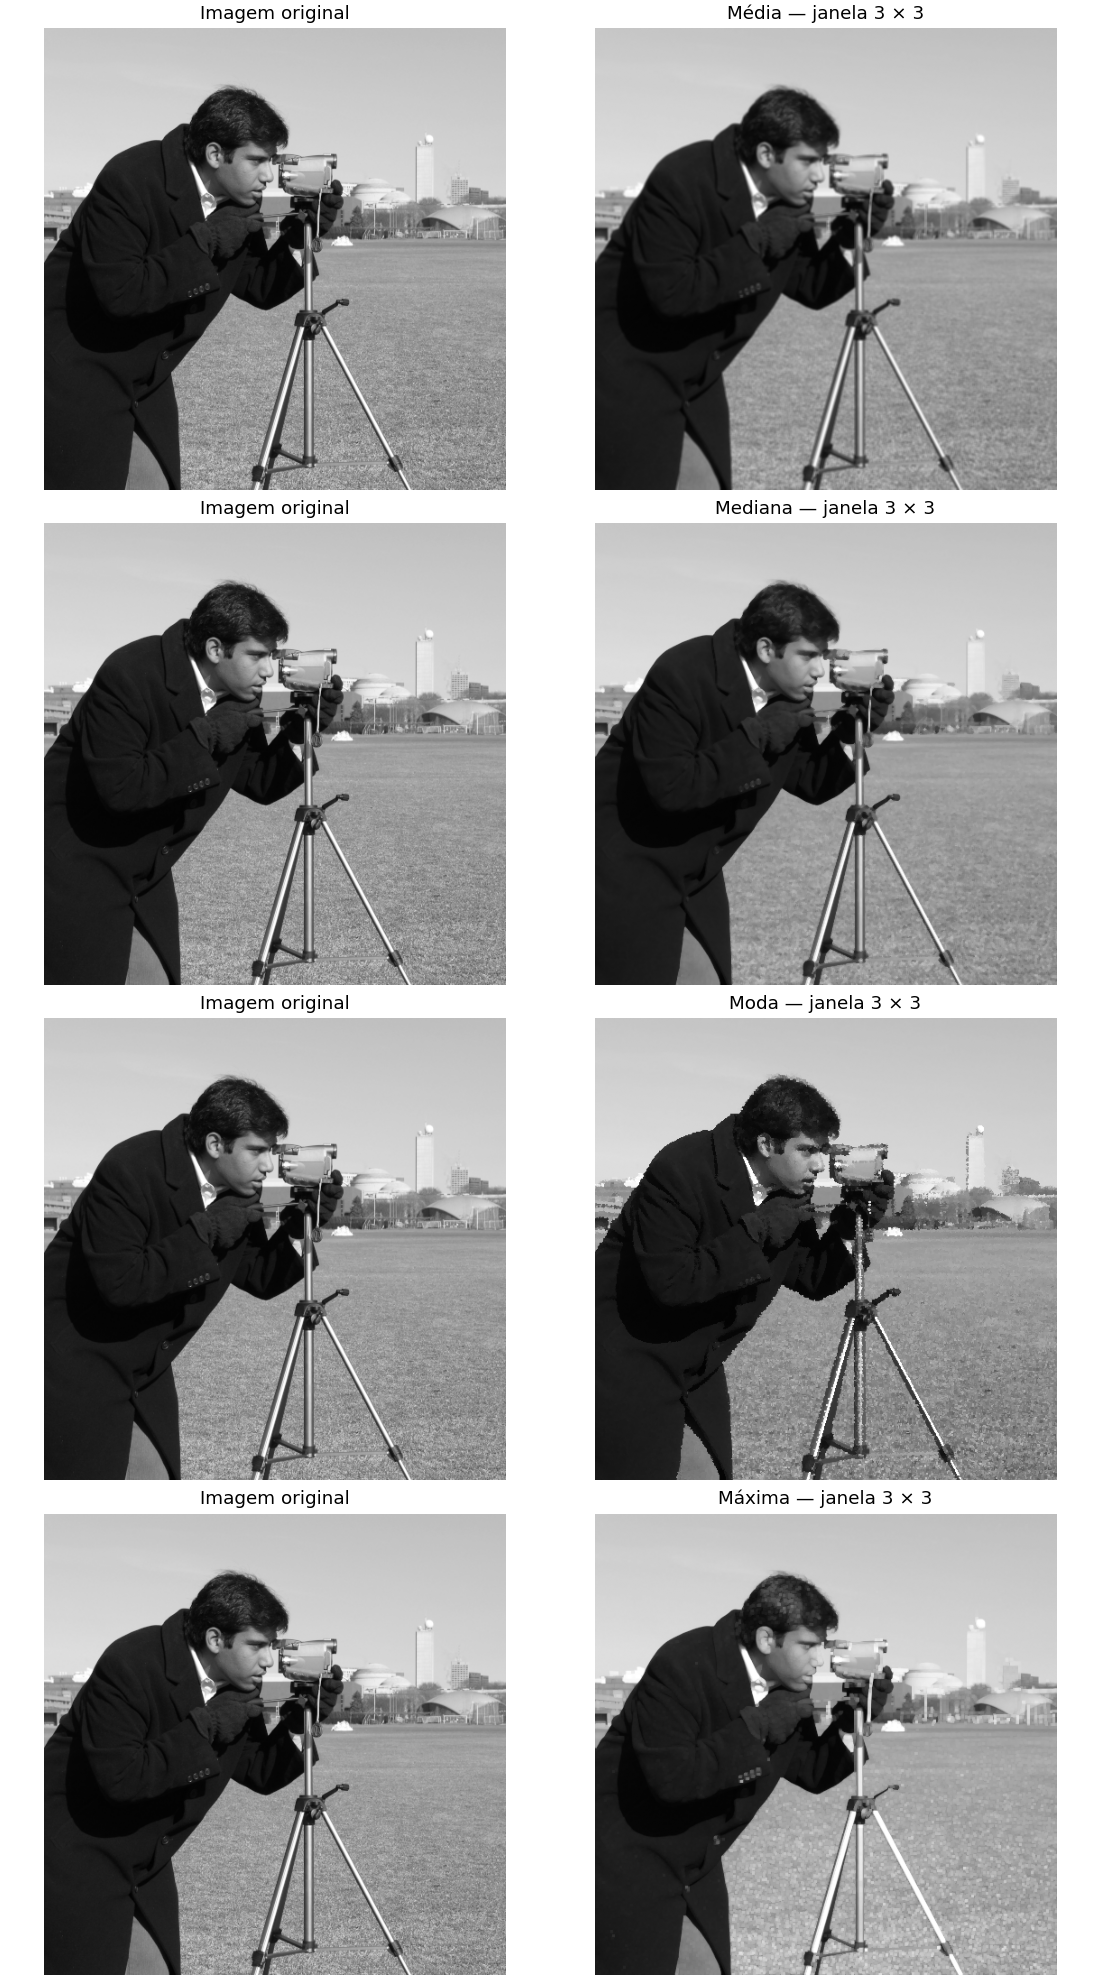

In [8]:
fig, eixos = plt.subplots(4, 2, figsize=(10, 18), constrained_layout=True)
for linha, (nome, filtrada) in enumerate(resultados.items()):
    eixos[linha, 0].imshow(imagem, cmap="gray", vmin=0, vmax=255)
    eixos[linha, 0].set_title("Imagem original")
    eixos[linha, 1].imshow(filtrada, cmap="gray", vmin=0, vmax=255)
    eixos[linha, 1].set_title(f"{nome} — janela {tamanho_janela} × {tamanho_janela}")
    for eixo in eixos[linha]:
        eixo.axis("off")
plt.show()

## 8. Interpretação
- **Média:** suaviza variações de intensidade, mas também desfoca bordas e detalhes.
- **Mediana:** costuma preservar melhor as bordas e é útil contra ruído impulsivo (sal e pimenta).
- **Moda:** favorece os níveis mais frequentes da vizinhança; o critério de desempate pode escurecer regiões com muitos valores distintos.
- **Máxima:** expande regiões claras e reduz pequenos pontos escuros; não é um suavizador equivalente à média.

Somente a média é um filtro linear entre os quatro implementados.